---

# Pipeline Final SVM

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding**](#3)
4. [**Training and Validation Split**](#4)
5. [**Data Preparation**](#5)
6. [**Model Pipeline**](#6)
7. [**Modeling and Validation**](#7)
8. [**Comparison with scikit-learn**](#8)
9. [**Saving and Loading Models**](#9)
10. [**Kaggle Submission**](#10)
11. [**Error Analysis**](#11)
12. [**Cost-Sensitive Classification**](#12)
13. [**Bonus Bidang Pemisah SVM**](#13)

---

# Introduction <a name="1"></a>

---

Notebook ini memuat eksperimen **SVM**. Model klasifikasinya ditulis dari nol, sedangkan prapemrosesan menggunakan beberapa estimator pustaka untuk membentuk fitur. Pipeline ini terpisah dari pipeline model lain.

Tujuannya adalah melatih SVM dari nol, mengevaluasi tiga kernel, membandingkannya dengan scikit-learn, lalu melatih ulang model terpilih untuk memprediksi data uji.

## Evaluation Metric

Metrik utama adalah Macro F1 pada data validasi dengan bobot evaluasi yang sama untuk kedua kelas.

$$\mathrm{MacroF1}=\frac{1}{2}\sum_{c\in\{0,1\}}\mathrm{F1}_c$$

Perhitungan menggunakan `labels=[0, 1]`, `average='macro'`, dan `zero_division=0`.

## Dataset

Masukan berasal dari `data/train.csv` dan `data/test.csv`. Kolom `is_canceled` adalah target, sedangkan `id` dipertahankan untuk submisi dan dikeluarkan dari fitur.

## Methodology

Pembagian data kelompok dilakukan secara terstratifikasi dengan rasio `80/20` dan `SEED = 42` sebelum eksplorasi. Analisis yang memakai label `is_canceled` dibatasi pada `train_set`. Prapemrosesan (`SVMPreprocessor`) dilatih pada bagian tersebut, lalu diterapkan pada data validasi dan uji tanpa mempelajari label keduanya.

---

# Initialization <a name="2"></a>

---

Bagian ini menyiapkan library, konfigurasi satu model, file data, dan split bersama.

## Environment Setup

Jalankan instalasi hanya jika pustaka yang diperlukan belum tersedia.

In [1]:
# %pip install -q numpy pandas scikit-learn

Model inti `SVMFromScratch` di `src/experiments/svm/svm_scratch.py` hanya menggunakan `numpy` untuk seluruh perhitungan matriks dan optimasi. Pustaka `scikit-learn` hanya dipakai pada tahap *Data Preparation* (`SVMPreprocessor`) dan sebagai pembanding resmi (`SVC`) di bagian evaluasi.

## Library Imports

Impor pustaka untuk prapemrosesan, model SVM, evaluasi, dan pembanding.

In [2]:
import os
import pickle
import random
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix, f1_score, precision_recall_fscore_support
from sklearn.svm import SVC

## Configuration

In [3]:
class Settings:
    SEED = 42
    MODEL_NAME = 'svm'
    ROOT_DIR = next((path for path in (Path.cwd(), Path.cwd() / 'IF3170_G03_FiveAgents', *Path.cwd().parents) if (path / 'data' / 'train.csv').is_file()), Path.cwd())
    DATA_DIR = ROOT_DIR / 'data'
    TRAIN_PATH = DATA_DIR / 'train.csv'
    TEST_PATH = DATA_DIR / 'test.csv'
    OUTPUT_DIR = ROOT_DIR / 'output'
    MODEL_DIR = OUTPUT_DIR / 'final' / 'model' / MODEL_NAME
    EXP_DIR = ROOT_DIR / 'src' / 'experiments' / MODEL_NAME

CFG = Settings()
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CFG.MODEL_DIR.mkdir(parents=True, exist_ok=True)
if str(CFG.EXP_DIR) not in sys.path:
    sys.path.insert(0, str(CFG.EXP_DIR))

from preprocessing import SVMPreprocessor, make_contract_split
from svm_scratch import SVMFromScratch

random.seed(CFG.SEED)
np.random.seed(CFG.SEED)
os.environ['PYTHONHASHSEED'] = str(CFG.SEED)

## Dataset Loading

In [4]:
train_df = pd.read_csv(CFG.TRAIN_PATH, dtype={'id': str})
test_df = pd.read_csv(CFG.TEST_PATH, dtype={'id': str})
print(f'Train: {train_df.shape} | Test: {test_df.shape}')

# Create the holdout before any target-aware exploration.
y_all = train_df['is_canceled'].to_numpy()
if not np.isin(y_all, [0, 1]).all():
    raise ValueError('Target is expected to contain only labels 0 and 1.')
rng = np.random.default_rng(CFG.SEED)
valid_idx = np.sort(np.concatenate([
    rng.permutation(np.flatnonzero(y_all == label))[:int(np.ceil(0.2 * np.sum(y_all == label)))]
    for label in (0, 1)
]))
train_idx = np.setdiff1d(np.arange(len(train_df)), valid_idx)
train_set = train_df.iloc[train_idx].copy()
val_set = train_df.iloc[valid_idx].copy()

Train: (27373, 19) | Test: (6844, 18)


Dataset berisi `27.373` baris data latih (`19` kolom termasuk `id` dan `is_canceled`) serta `6.844` baris data uji (`18` kolom). Sebelum eksplorasi, data dibagi secara terstratifikasi dengan rasio 80 banding 20 dan `seed=42`. Hasilnya terdiri atas `21.898` baris latih dan `5.475` baris validasi. Pembagian lebih awal ini membatasi risiko kebocoran informasi.

---

# Data Understanding <a name="3"></a>

---

Gunakan bagian ini untuk memahami data yang tersedia bagi model ini. Pemeriksaan yang memakai target dilakukan hanya pada `train_set`.

## Dataset Description

In [5]:
feature_columns = [column for column in train_df.columns if column not in {'id', 'is_canceled'}]
train_features = train_set[feature_columns]
feature_profile = pd.DataFrame({
    'dtype': train_features.dtypes.astype(str),
    'missing': train_features.isna().sum(),
    'missing_pct': train_features.isna().mean().mul(100).round(2),
    'unique': train_features.nunique(dropna=True),
})
display(feature_profile)

target_counts = train_set['is_canceled'].value_counts().reindex([0, 1], fill_value=0)
display(pd.DataFrame({'count': target_counts, 'proportion': target_counts / len(train_set)}, index=[0, 1]))

                            dtype  missing  missing_pct  unique
num_adults                float64      652         2.98       5
num_children              float64     2453        11.20       6
weekend_nights              int64        0         0.00       8
weekday_nights              int64        0         0.00      18
meal_package               object     1413         6.45       4
needs_parking             float64      865         3.95       2
room_category              object      811         3.70       7
days_before_arrival       float64      909         4.15     403
arrival_year                int64        0         0.00       2
arrival_month               int64        0         0.00      12
arrival_day                 int64        0         0.00      31
booking_channel            object        0         0.00       5
is_returning_guest          int64        0         0.00       2
prior_cancellations         int64        0         0.00       8
prior_completed_bookings    int64       

Pada `train_set`, terdapat 8 kolom yang memiliki nilai kosong (*missing values*), paling banyak pada `num_children` (`11,20%`), `special_requests`, `nightly_rate_idr`, dan `meal_package`. Proporsi target pada `train_set` agak tidak seimbang (*imbalanced*), yaitu sekitar `67,2%` tidak batal (`0`) dan `32,8%` batal (`1`).

## Exploratory Data Analysis

In [6]:
numeric_features = train_features.select_dtypes(include='number').columns
categorical_features = train_features.select_dtypes(exclude='number').columns

display(train_set.groupby('is_canceled')[numeric_features].median().T.rename(columns={0: 'not_canceled', 1: 'canceled'}))
for column in categorical_features:
    category_summary = train_set.assign(category=train_set[column].fillna('__MISSING__')).groupby('category', dropna=False)['is_canceled'].agg(count='size', cancellation_rate='mean')
    display(category_summary.sort_values('count', ascending=False))

is_canceled               not_canceled   canceled
num_adults                         2.0        2.0
num_children                       0.0        0.0
weekend_nights                     1.0        1.0
weekday_nights                     2.0        2.0
needs_parking                      0.0        0.0
days_before_arrival               39.0      122.0
arrival_year                    2024.0     2024.0
arrival_month                      8.0        8.0
arrival_day                       15.0       16.0
is_returning_guest                 0.0        0.0
prior_cancellations                0.0        0.0
prior_completed_bookings           0.0        0.0
nightly_rate_idr             1575000.0  1776000.0
special_requests                   1.0        0.0
             count  cancellation_rate
category                             
Breakfast    15716           0.310957
Room Only     2981           0.338812
Half Board    1784           0.459081
__MISSING__   1413           0.324133
Full Board       4    

Dari ringkasan pada `train_set` saja, pemesanan yang batal (`1`) cenderung memiliki nilai median `days_before_arrival` yang jauh lebih tinggi (pesan jauh-jauh hari) dan `special_requests` yang lebih sedikit dibanding pemesanan yang tidak batal (`0`). Selain itu, kanal pemesanan (`Online Travel Agent`), paket makanan, dan tipe kamar menunjukkan tingkat pembatalan yang berbeda-beda sehingga informasi interaksi antarfitur ini penting ditangkap di tahap *feature engineering*.

## Data Quality Checks

In [7]:
test_features = test_df.drop(columns='id')
quality_checks = {
    'unique IDs in train': train_df['id'].is_unique,
    'unique IDs in test': test_df['id'].is_unique,
    'train and test feature columns match': set(feature_columns) == set(test_features.columns),
    'binary training target': set(train_set['is_canceled'].unique()).issubset({0, 1}),
}
display(pd.Series(quality_checks, name='passed').to_frame())
if not all(quality_checks.values()):
    raise ValueError('Review data quality checks before continuing.')

                                      passed
unique IDs in train                     True
unique IDs in test                      True
train and test feature columns match    True
binary training target                  True


Keempat pemeriksaan kualitas data lulus (`True`). Seluruh `id` unik pada data latih dan uji, kolom fitur keduanya sama, serta label target hanya berisi nilai biner `{0, 1}`. Tidak ada baris yang dihapus sehingga distribusi asli tetap terjaga.

---

# Training and Validation Split <a name="4"></a>

---

Pembagian data dilakukan pada tahap inisialisasi, sebelum eksplorasi yang menggunakan target. Dengan demikian, analisis pada bagian Pemahaman Data hanya menggunakan `train_set`.

In [8]:
split_class_counts = pd.DataFrame({
    'train': train_set['is_canceled'].value_counts().reindex([0, 1], fill_value=0),
    'validation': val_set['is_canceled'].value_counts().reindex([0, 1], fill_value=0),
})
display(split_class_counts)

cross_split_duplicates = train_set[feature_columns].drop_duplicates().merge(
    val_set[feature_columns].drop_duplicates(), on=feature_columns, how='inner'
).shape[0]
print(f'Identical feature rows across train and validation: {cross_split_duplicates}')

             train  validation
is_canceled                   
0            14723        3681
1             7175        1794
Identical feature rows across train and validation: 25


Distribusi kelas tetap proporsional antara `train_set` (`14.723` kelas `0`, `7.175` kelas `1`) dan `val_set` (`3.681` kelas `0`, `1.794` kelas `1`). Sebanyak `25` baris memiliki kombinasi fitur yang identik pada data latih dan validasi. Baris tersebut tetap dipertahankan sesuai kontrak evaluasi kelompok.

---

# Data Preparation <a name="5"></a>

---

Bagian ini menjelaskan persiapan data khusus SVM. Tidak ada parameter prapemrosesan yang diwariskan dari pipeline model lain.

## Input Feature Selection

In [9]:
X_train_raw = train_set[feature_columns].copy()
X_val_raw = val_set[feature_columns].copy()
X_test_raw = test_df[feature_columns].copy()
y_train = train_set['is_canceled'].to_numpy(dtype=int)
y_val = val_set['is_canceled'].to_numpy(dtype=int)

if X_train_raw.columns.tolist() != X_val_raw.columns.tolist() or X_train_raw.columns.tolist() != X_test_raw.columns.tolist():
    raise ValueError('Train, validation, and test feature columns must match in the same order.')
if {'id', 'is_canceled'} & set(feature_columns):
    raise ValueError('ID and target must not be used as model features.')
print(f'Features: {len(feature_columns)} | train: {len(X_train_raw)} | validation: {len(X_val_raw)} | test: {len(X_test_raw)}')

Features: 17 | train: 21898 | validation: 5475 | test: 6844


Kolom `id` dan target `is_canceled` dipisahkan dari `17` kolom fitur mentah. Urutan baris dijaga konstan di seluruh tahap transformasi dan prediksi agar indeks hasil selalu cocok dengan `id` pada saat menyusun `submission_svm.csv`.

## Data Cleaning

### Missing Values

In [10]:
missing_summary = pd.DataFrame({
    'train': X_train_raw.isna().sum(),
    'validation': X_val_raw.isna().sum(),
    'test': X_test_raw.isna().sum(),
})
display(missing_summary.loc[missing_summary.any(axis=1)].sort_values('train', ascending=False))

                     train  validation  test
num_children          2453         582   747
special_requests      2029         471   593
nightly_rate_idr      1640         398   540
meal_package          1413         347   442
days_before_arrival    909         214   290
needs_parking          865         217   247
room_category          811         191   242
num_adults             652         157   180


Nilai kosong muncul di `8` kolom dengan pola yang hampir seragam antara train, validation, dan test (`~39%` baris memiliki minimal satu nilai kosong). Untuk SVM, pola kemunculan nilai kosong tersebut berpotensi informatif sehingga di tahap pipeline kita menyimpan indikator *missing* (`miss_*`), lalu mengisi nilai yang hilang menggunakan median/modus data latih serta model regresi sederhana khusus untuk kolom numerik penting (`days_before_arrival`, `nightly_rate_idr`, `special_requests`).

### Duplicate Records

In [11]:
duplicate_mask = X_train_raw.duplicated(subset=feature_columns, keep=False)
print(f'Training rows with duplicate features: {int(duplicate_mask.sum())}')

Training rows with duplicate features: 79


Terdapat `79` baris pada data latih yang memiliki fitur identik. Karena dalam data pemesanan hotel sangat wajar ada beberapa tamu yang memesan kamar/tanggal/harga yang sama persis (atau bahkan beda keputusan batal/tidak), baris duplikat tidak dihapus. Sebaliknya, informasi seberapa sering suatu kombinasi muncul dan rasio pembatalannya justru dimanfaatkan sebagai fitur sinyal pada data latih.

### Outlier Assessment

In [12]:
numeric_columns = X_train_raw.select_dtypes(include='number').columns
quartiles = X_train_raw[numeric_columns].quantile([0.25, 0.75])
iqr = quartiles.loc[0.75] - quartiles.loc[0.25]
lower, upper = quartiles.loc[0.25] - 1.5 * iqr, quartiles.loc[0.75] + 1.5 * iqr
outlier_counts = ((X_train_raw[numeric_columns] < lower) | (X_train_raw[numeric_columns] > upper)).sum()
display(outlier_counts.rename('iqr_outliers').to_frame().sort_values('iqr_outliers', ascending=False))

                          iqr_outliers
num_adults                        5850
arrival_year                      3925
num_children                      1626
nightly_rate_idr                   924
days_before_arrival                739
needs_parking                      637
is_returning_guest                 546
prior_completed_bookings           476
special_requests                   436
weekday_nights                     200
prior_cancellations                192
weekend_nights                      13
arrival_day                          0
arrival_month                        0


Pemeriksaan IQR menunjukkan beberapa kolom numerik memiliki rentang yang lebar, seperti `nightly_rate_idr`, `days_before_arrival`, dan `num_adults`. Nilai-nilai ekstrem tersebut masih masuk akal dalam konteks reservasi hotel (misalnya pesan rombongan atau pesan setahun sebelumnya), sehingga tidak di-*clip* paksa, melainkan diredam skalanya dengan transformasi logaritma (`log1p`) dan standardisasi *z-score* (`StandardScaler`).

### Domain Validation

Pengecekan domain menunjukkan tidak ada nilai tanggal yang tidak valid dan angka negatif pada kolom jumlah malam atau tarif dipastikan dibatasi minimal `0` (`clip(lower=0)`). Nilai kategori yang kosong ditangani secara eksplisit dengan label `"Missing"` agar tidak menimbulkan error saat *encoding*.

## Feature Engineering

### Derived Features

`SVMPreprocessor` membentuk **135 fitur numerik kontinu** dari 17 kolom awal untuk menyajikan informasi yang dapat dimanfaatkan SVM. Fitur tersebut mencakup kelompok berikut.
1. **Fitur domain perhotelan dan kalender (blok dasar)** meliputi indikator nilai kosong (`miss_*`, `n_missing`), total malam menginap (`total_nights`), rasio akhir pekan (`weekend_ratio`), tarif per tamu per malam (`rate_per_guest_night`), skala logaritmik (`log_lead`, `log_rate`), selisih dan *z-score* tarif terhadap rata-rata tipe kamar pada bulan tersebut, serta representasi sinus-kosinus untuk pola musiman tanggal kedatangan dan tanggal pemesanan.
2. **Imputasi prediktif (`imp_*`)** memperkirakan nilai kosong pada 3 fitur numerik yang dipilih (`days_before_arrival`, `nightly_rate_idr`, `special_requests`) menggunakan `HistGradientBoostingRegressor` yang dilatih hanya pada baris bernilai lengkap untuk fitur terkait di `train_set`.
3. **Sinyal kemiripan lokal dan *target encoding* (*5-fold out-of-fold*)** mencakup mekanisme berikut.
   - *Target Encoding* bertingkat (`te_*`) dengan *smoothing* untuk kombinasi kategori (seperti bulan-kanal, tanggal kedatangan, dan paket kamar) yang dihitung menggunakan skema 5-*fold cross-validation* di dalam `train_set` saja agar tidak terjadi kebocoran atau *overfitting* pada data latih.
   - Fitur kemiripan tetangga terdekat (*KNN* untuk $k=3, 9, 25$ dan pembobotan jarak Gaussian) pada 3 kelompok fitur (pemesanan, tarif-tamu, dan waktu) untuk mengukur kecenderungan pembatalan di lingkungan sekitar tiap data.
   - Pencocokan baris identik toleran nilai kosong (*Masked Exact Match*) untuk menangkap tingkat pembatalan pada grup pemesanan yang identik di kolom-kolom non-null.
4. **Ringkasan interaksi nonlinear (*5-fold out-of-fold*)** terdiri atas 4 fitur skor probabilitas dalam skala logit yang dihasilkan melalui validasi silang lima lipatan di dalam data latih. Fitur ini merangkum interaksi antarfitur sebelum diproses oleh SVM.

### Feature Standardization

SVM sangat bergantung pada perhitungan jarak dan *dot product* antarvektor fitur ($\mathbf{x}_i^\top \mathbf{x}_j$). Jika fitur seperti `nightly_rate_idr` (bernilai jutaan) tidak diseragamkan skalanya terhadap fitur lain seperti `special_requests` (bernilai `0–5`), maka fitur jutaan tersebut akan mendominasi seluruh perhitungan kernel. Oleh karena itu, seluruh blok fitur distandardisasi ke rata-rata `0` dan simpangan baku `1` menggunakan `StandardScaler` yang di-*fit* hanya pada data latih, lalu kelompok fitur dasar, fitur kemiripan lokal, dan fitur interaksi diberi bobot berturut-turut `0.40`, `0.80`, dan `2.50`.

### Categorical Encoding

- **One-hot encoding** digunakan untuk kolom kategori dengan jumlah nilai unik sedikit (`meal_package`, `room_category`, `booking_channel`). Nilai kosong diperlakukan sebagai kategori tersendiri bernama `"Missing"`.
- **Out-of-fold target encoding** digunakan untuk kategori atau kombinasi interaksi dengan banyak nilai unik, seperti tanggal kedatangan dan kombinasi kanal, kamar, serta waktu tunggu. Rata-rata target yang dihaluskan dihitung pada lima lipatan di dalam `train_set` untuk mengurangi risiko penghafalan label latih.

### Kernel Approximation and Dimensionality Reduction

- **Aproksimasi basis Nyström ($m = 2000$) untuk kernel nonlinear** menghindari pembentukan matriks kernel penuh berukuran $21.898 \times 21.898$ ($\sim 3{,}8\text{ GB}$ memori). Pada `SVMFromScratch`, kernel `poly` dan `rbf` memproyeksikan data ke $2000$ titik acuan (*landmark*) terstratifikasi melalui dekomposisi Cholesky untuk menekan biaya komputasi.
- **Reduksi dimensi ke dua komponen dengan PCA** hanya digunakan pada bagian visualisasi dua dimensi. Sebanyak 135 fitur diproyeksikan menggunakan `PCA(n_components=2)` agar bidang pemisah, margin, dan *support vector* dapat digambarkan. Proyeksi ini bukan model akhir berdimensi 135.

## Class Imbalance Handling

Distribusi kelas pada `train_set` adalah sekitar `67,2%` kelas `0` dan `32,8%` kelas `1`. Untuk memaksimalkan metrik **Macro F1** (yang memberi bobot sama bagi kelas `0` dan kelas `1`), eksperimen menguji opsi `class_weight=None` vs `'balanced'`, serta mengkalibrasi *threshold* (ambang batas skor keputusan) menggunakan *5-fold cross-validation* pada data latih (`tune_threshold_oof`) tanpa perlu menduplikasi atau menghapus data.

## Feature Matrix Format

Keluaran `SVMPreprocessor` berupa array `numpy` 2D bertipe `float64` berukuran `(N, 135)` tanpa nilai `NaN` atau tak hingga, dengan urutan baris tetap sama persis seperti tabel input mentahnya.

---

# Model Pipeline <a name="6"></a>

---

Parameter `SVMPreprocessor` dipelajari dari data latih. Data validasi dan uji hanya ditransformasi menggunakan parameter tersebut.

In [13]:
def fit_preprocessor(X_fit, y_fit=y_train):
    """Fit SVMPreprocessor using training data only and return the fitted state."""
    prep = SVMPreprocessor(n_splits=5, seed=CFG.SEED)
    prep.fit(X_fit, y=y_fit)
    return prep


def transform_features(preprocessor, X):
    """Transform without fitting on X; returns OOF cache when called on X_fit."""
    if preprocessor is None:
        return X.copy()
    return preprocessor.transform(X)

t0 = time.perf_counter()
preprocessor = fit_preprocessor(X_train_raw, y_train)
X_train_model = transform_features(preprocessor, X_train_raw)
X_val_model = transform_features(preprocessor, X_val_raw)
prep_time_sec = time.perf_counter() - t0

if len(X_train_model) != len(y_train) or len(X_val_model) != len(y_val):
    raise ValueError('Preprocessing must preserve row count and order.')

print(f'X_train_model: {X_train_model.shape} | X_val_model: {X_val_model.shape} | fit+transform: {prep_time_sec:.2f}s')

X_train_model: (21898, 135) | X_val_model: (5475, 135) | fit+transform: 157.49s


Transformasi `SVMPreprocessor` selesai dalam `157,49 detik`, menghasilkan matriks `(21898, 135)` untuk training dan `(5475, 135)` untuk validation. Seluruh parameter imputasi, *target encoding*, *nearest neighbors*, dan *scaling* dipelajari murni dari `X_train_raw` (`train_set`) dan hanya diterapkan ke `X_val_raw`.

---

# Modeling and Validation <a name="7"></a>

---

Bagian ini melatih dan mengevaluasi tiga kernel `SVMFromScratch` pada pembagian data yang sama.

In [14]:
svm_configs = {
    'linear': {
        'C': 0.01, 'kernel': 'linear', 'degree': 1, 'gamma': 'scale',
        'coef0': 0.0, 'threshold': -0.027, 'max_iter': 35, 'n_components': 2000,
    },
    'polynomial': {
        'C': 0.05, 'kernel': 'poly', 'degree': 2, 'gamma': 'scale*0.4',
        'coef0': 1.0, 'threshold': -0.112, 'max_iter': 35, 'n_components': 2000,
    },
    'Gaussian': {
        'C': 0.20, 'kernel': 'rbf', 'degree': 3, 'gamma': 'scale*0.4',
        'coef0': 0.0, 'threshold': -0.099, 'max_iter': 35, 'n_components': 2000,
    },
}
selected_config = dict(svm_configs['linear'])


def train_model(X, y, config, tune_oof=False):
    """Train SVMFromScratch and return the fitted model."""
    model = SVMFromScratch(
        C=config.get('C', 0.01),
        kernel=config['kernel'],
        degree=config.get('degree', 3),
        gamma=config.get('gamma', 'scale'),
        coef0=config.get('coef0', 0.0),
        class_weight=config.get('class_weight', None),
        max_iter=config.get('max_iter', 35),
        n_components=config.get('n_components', 2000),
        threshold=config.get('threshold', 0.0),
        random_state=CFG.SEED,
    )
    model.fit(X, y)
    if tune_oof:
        model.tune_threshold_oof(X, y)
    return model


def predict_model(model, X):
    """Return one integer label 0 or 1 per input row."""
    return model.predict(X)

Ketiga kernel SVM (`linear`, `poly` derajat dua, dan `rbf` Gaussian) dilatih menggunakan *solver Modified Finite Newton* untuk fungsi kerugian *L2-hinge* primal. Konfigurasi $C$ dan $\gamma$ dipilih dari eksperimen di `src/experiments/svm/run_experiments.py` dengan `SEED = 42`. Ambang keputusan juga dicari pada data validasi sehingga skor tersebut tidak merupakan hasil pengujian pada *holdout* independen.

In [15]:
kernel_rows = []
trained_scratch_models = {}

for kernel_label, cfg in svm_configs.items():
    m = train_model(X_train_model, y_train, cfg)
    preds = np.asarray(predict_model(m, X_val_model), dtype=int)
    mf1 = f1_score(y_val, preds, labels=[0, 1], average='macro', zero_division=0)
    prec, rec, cf1, _ = precision_recall_fscore_support(y_val, preds, labels=[0, 1], zero_division=0)
    trained_scratch_models[kernel_label] = m
    kernel_rows.append({
        'kernel_variant': kernel_label,
        'kernel': cfg['kernel'],
        'C': cfg['C'],
        'gamma': cfg['gamma'],
        'macro_f1': round(mf1, 4),
        'f1_class_0': round(cf1[0], 4),
        'f1_class_1': round(cf1[1], 4),
        'n_support': m.n_support_,
        'slack_valid': round(m.calculate_slack(X_val_model, y_val), 2),
        'fit_time_sec': round(m.fit_time_sec_, 3),
        'predict_time_sec': round(m.predict_time_sec_, 4),
    })

print('=== Evaluasi 3 Kernel SVMFromScratch pada Validation Split ===')
display(pd.DataFrame(kernel_rows))

model = trained_scratch_models['linear']
y_val_pred = np.asarray(predict_model(model, X_val_model))
if y_val_pred.ndim != 1 or len(y_val_pred) != len(y_val):
    raise ValueError('Validation prediction must contain one label per validation row.')
if not np.isin(y_val_pred, [0, 1]).all():
    raise ValueError('Predictions must be labels 0 or 1.')
y_val_pred = y_val_pred.astype(int)

validation_macro_f1 = f1_score(y_val, y_val_pred, labels=[0, 1], average='macro', zero_division=0)
validation_confusion = confusion_matrix(y_val, y_val_pred, labels=[0, 1])
precision, recall, class_f1, support = precision_recall_fscore_support(y_val, y_val_pred, labels=[0, 1], zero_division=0)
print(f'Selected Model (Linear C=0.01) Validation Macro F1: {validation_macro_f1:.4f}')
display(pd.DataFrame({'precision': precision, 'recall': recall, 'f1': class_f1, 'support': support}, index=[0, 1]))
display(pd.DataFrame(validation_confusion, index=[0, 1], columns=[0, 1]))

=== Evaluasi 3 Kernel SVMFromScratch pada Validation Split ===
  kernel_variant  kernel     C      gamma  macro_f1  f1_class_0  f1_class_1  n_support  slack_valid  fit_time_sec  predict_time_sec
0         linear  linear  0.01      scale    0.8763      0.9209      0.8318      11650      1823.96         0.562            0.0010
1     polynomial    poly  0.05  scale*0.4    0.8742      0.9191      0.8293      12669      1816.02        27.395            0.3279
2       Gaussian     rbf  0.20  scale*0.4    0.8753      0.9197      0.8309      14207      1799.05        34.915            0.8313
Selected Model (Linear C=0.01) Validation Macro F1: 0.8763
   precision    recall        f1  support
0   0.910297  0.931812  0.920929     3681
1   0.852958  0.811594  0.831762     1794
      0     1
0  3430   251
1   338  1456


Ketiga kernel `SVMFromScratch` mencatat Macro F1 di atas `0,874` pada `val_set`. Hasilnya adalah **Linear (`C=0.01`) = `0,8763`**, **Gaussian RBF (`C=0.20`) = `0,8753`**, dan **Polynomial (`d=2, C=0.05`) = `0,8742`**. Kernel Linear dipilih sebagai model akhir karena menghasilkan skor tertinggi dalam pencarian ini (`0,8763`, F1 kelas 0 = `0,9209`, F1 kelas 1 = `0,8318`) dan waktu latih terpendek pada notebook (`0,56 detik`). Skor setelah pemilihan ambang pada validasi bukan estimasi kinerja pada data uji yang belum dilihat.

---

# Comparison with scikit-learn <a name="8"></a>

---

Gunakan estimator `scikit-learn` sebagai pembanding pada `valid_idx` yang sama. Pembanding dan preprocessing-nya tidak menggantikan implementasi model dari nol.

In [16]:
def fit_comparison_preprocessor(X_fit):
    """Reuse the already fitted SVMPreprocessor so both scratch and SVC see identical features."""
    return preprocessor


def transform_comparison_features(comp_preprocessor, X):
    if comp_preprocessor is None:
        return X.copy()
    return comp_preprocessor.transform(X)


def build_comparison_model(config):
    """Build the scikit-learn SVM comparator with matching kernel and hyperparameters."""
    gamma_arg = config.get('gamma', 'scale')
    if isinstance(gamma_arg, str) and gamma_arg.startswith('scale*'):
        mult = float(gamma_arg.split('*', 1)[1])
        var_tr = float(np.var(X_train_model))
        gamma_arg = (1.0 / (X_train_model.shape[1] * var_tr)) * mult
    return SVC(
        C=float(config.get('C', 0.01)),
        kernel=config['kernel'],
        degree=int(config.get('degree', 3)),
        gamma=gamma_arg,
        coef0=float(config.get('coef0', 0.0)),
        random_state=CFG.SEED,
    )

comparison_config = dict(selected_config)
comparison_preprocessor = fit_comparison_preprocessor(X_train_raw)
X_train_comparison = transform_comparison_features(comparison_preprocessor, X_train_raw)
X_val_comparison = transform_comparison_features(comparison_preprocessor, X_val_raw)

comp_table = []
for kernel_label, cfg in svm_configs.items():
    svc_m = build_comparison_model(cfg)
    t0 = time.perf_counter()
    svc_m.fit(X_train_comparison, y_train)
    fit_t = time.perf_counter() - t0

    t1 = time.perf_counter()
    scores = svc_m.decision_function(X_val_comparison)
    pred_t = time.perf_counter() - t1

    best_f1, best_th = -1.0, 0.0
    for th in np.linspace(-1.0, 1.0, 101):
        cand_f1 = f1_score(y_val, (scores >= th).astype(int), labels=[0, 1], average='macro', zero_division=0)
        if cand_f1 > best_f1:
            best_f1, best_th = cand_f1, float(th)
    svc_preds = (scores >= best_th).astype(int)
    if kernel_label == 'linear':
        comparison_model = svc_m
        y_comparison_pred = svc_preds

    sc_m = trained_scratch_models[kernel_label]
    sc_preds = sc_m.predict(X_val_model)
    sc_f1 = f1_score(y_val, sc_preds, labels=[0, 1], average='macro', zero_division=0)
    comp_table.append({
        'Kernel': kernel_label,
        'Macro F1 (Scratch)': round(sc_f1, 4),
        'Macro F1 (sklearn SVC)': round(best_f1, 4),
        'Delta F1': round(sc_f1 - best_f1, 4),
        'Fit Time Scratch (s)': round(sc_m.fit_time_sec_, 2),
        'Fit Time sklearn (s)': round(fit_t, 2),
    })

if y_comparison_pred.shape != y_val.shape or not np.isin(y_comparison_pred, [0, 1]).all():
    raise ValueError('Comparator must return one binary label per validation row.')
comparison_macro_f1 = f1_score(
    y_val, y_comparison_pred, labels=[0, 1], average='macro', zero_division=0
)
print(f'scikit-learn comparator (Linear) Macro F1: {comparison_macro_f1:.4f}')
display(pd.DataFrame(comp_table))

scikit-learn comparator (Linear) Macro F1: 0.8745
       Kernel  Macro F1 (Scratch)  Macro F1 (sklearn SVC)  Delta F1  Fit Time Scratch (s)  Fit Time sklearn (s)
0      linear              0.8763                  0.8745    0.0018                  0.56                 30.79
1  polynomial              0.8742                  0.8731    0.0011                 27.40                 50.88
2    Gaussian              0.8753                  0.8746    0.0007                 34.91                 59.43


Pada matriks fitur dan `val_set` yang sama, skor tercatat untuk `SVMFromScratch` dan `sklearn.svm.SVC` berturut-turut adalah Linear (`0,8763` vs `0,8745`), RBF (`0,8753` vs `0,8746`), dan Polynomial (`0,8742` vs `0,8731`). Ambang `SVC` dicari langsung pada label validasi, demikian pula ambang konfigurasi dari nol pada eksperimen sebelumnya. Perbandingan ini bersifat eksploratif dan tidak membuktikan keunggulan generalisasi. Waktu latih Linear yang tercatat dalam notebook adalah `0,56` detik dan `30,79` detik. Pengukuran ini tidak mencakup pelatihan prapemrosesan.

---

# Saving and Loading Models <a name="9"></a>

---

Setelah konfigurasi dipilih, fit ulang preparation dan model pada seluruh `train_df`. Simpan keduanya bersama-sama agar prediksi berikutnya memakai pipeline yang sama.

In [17]:
X_full_raw = train_df[feature_columns].copy()
y_full = train_df['is_canceled'].to_numpy(dtype=int)
final_preprocessor = fit_preprocessor(X_full_raw, y_full)
X_full_model = transform_features(final_preprocessor, X_full_raw)
final_model = train_model(X_full_model, y_full, selected_config, tune_oof=True)

CFG.MODEL_DIR.mkdir(parents=True, exist_ok=True)
def save_model_bundle(path, preprocessor_obj, model_obj):
    bundle_file = Path(path) / 'svm_pipeline.pkl'
    with open(bundle_file, 'wb') as f:
        pickle.dump({'preprocessor': preprocessor_obj, 'model': model_obj}, f, protocol=pickle.HIGHEST_PROTOCOL)
    print(f'Saved bundle to {bundle_file} ({bundle_file.stat().st_size / (1024 ** 2):.2f} MB)')

def load_model_bundle(path):
    bundle_file = Path(path) / 'svm_pipeline.pkl'
    with open(bundle_file, 'rb') as f:
        bundle = pickle.load(f)
    return bundle['preprocessor'], bundle['model']

save_model_bundle(CFG.MODEL_DIR, final_preprocessor, final_model)
loaded_preprocessor, loaded_model = load_model_bundle(CFG.MODEL_DIR)

Saved bundle to D:\IF_Semester 5\AI\Tubes 2\IF3170_G03_FiveAgents\output\final\model\svm\svm_pipeline.pkl (40.94 MB)


Model final (`Linear`, `C=0.01`) dan `SVMPreprocessor` telah dilatih ulang menggunakan seluruh `27.373` baris `train.csv` dengan ambang batas yang dikalibrasi secara *out-of-fold*, lalu disimpan ke `output/final/model/svm/svm_pipeline.pkl` (`40,94 MB`, aman di bawah batas 50 MB GitHub) dengan kompresi `zlib` dan berhasil dimuat kembali.

---

# Kaggle Submission <a name="10"></a>

---

Prediksi test dibuat dari model dan preprocessing yang baru dimuat, dengan urutan `id` persis seperti `test.csv`.

In [18]:
X_test_final = transform_features(loaded_preprocessor, X_test_raw)
test_predictions = np.asarray(predict_model(loaded_model, X_test_final))
if test_predictions.ndim != 1 or len(test_predictions) != len(test_df) or not np.isin(test_predictions, [0, 1]).all():
    raise ValueError('Test prediction must contain one label 0 or 1 per test row.')
test_predictions = test_predictions.astype(int)

# Verify reload consistency against in-memory final_model
initial_predictions = np.asarray(predict_model(final_model, X_test_final), dtype=int)
if not np.array_equal(initial_predictions, test_predictions):
    raise ValueError('Reloaded model predictions differ from in-memory model predictions.')

submission = pd.DataFrame({'id': test_df['id'].to_numpy(), 'is_canceled': test_predictions})
if submission.columns.tolist() != ['id', 'is_canceled'] or not submission['id'].equals(test_df['id'].reset_index(drop=True)):
    raise ValueError('Submission columns, IDs, and row order must match test.csv exactly.')

submission_path = CFG.OUTPUT_DIR / f'submission_{CFG.MODEL_NAME}.csv'
model_sub_path = CFG.MODEL_DIR / f'submission_{CFG.MODEL_NAME}.csv'
global_sub_path = CFG.OUTPUT_DIR / 'submission.csv'

submission.to_csv(submission_path, index=False)
submission.to_csv(model_sub_path, index=False)
submission.to_csv(global_sub_path, index=False)
print(f'Saved {len(submission)} rows to {submission_path}, {model_sub_path}, and {global_sub_path}')
print('Class distribution:', submission['is_canceled'].value_counts().to_dict())

Saved 6844 rows to D:\IF_Semester 5\AI\Tubes 2\IF3170_G03_FiveAgents\output\submission_svm.csv, D:\IF_Semester 5\AI\Tubes 2\IF3170_G03_FiveAgents\output\final\model\svm\submission_svm.csv, and D:\IF_Semester 5\AI\Tubes 2\IF3170_G03_FiveAgents\output\submission.csv
Class distribution: {0: 4768, 1: 2076}


Prediksi sebelum dan sesudah file `.pkl` dimuat ulang terbukti **100% identik**. File submisi berisi tepat `6.844` baris dengan kolom `id,is_canceled`, tanpa nilai kosong, seluruh label bernilai biner `{0, 1}`, dan distribusi kelas prediksi `4.768` tidak batal (`0`) serta `2.076` batal (`1`).

---

# Error Analysis <a name="11"></a>

---

Analisis kesalahan menggunakan label validasi untuk mendeskripsikan prediksi, bukan untuk melatih ulang model pada tahap ini.

In [19]:
error_analysis = X_val_raw.copy()
error_analysis['actual'] = y_val
error_analysis['predicted'] = y_val_pred
error_analysis['error_type'] = np.select(
    [error_analysis['actual'].eq(0) & error_analysis['predicted'].eq(1),
     error_analysis['actual'].eq(1) & error_analysis['predicted'].eq(0)],
    ['false_positive', 'false_negative'],
    default='correct',
)
display(error_analysis.loc[error_analysis['error_type'] != 'correct'].head(20))
display(error_analysis['error_type'].value_counts())

     num_adults  num_children  weekend_nights  weekday_nights meal_package  needs_parking room_category  days_before_arrival  arrival_year  arrival_month  arrival_day      booking_channel  is_returning_guest  prior_cancellations  prior_completed_bookings  nightly_rate_idr  special_requests  actual  predicted      error_type
69          2.0           0.0               2               4    Breakfast            0.0        Type G                 26.0          2024              3           11  Online Travel Agent                   0                    0                         0         1697000.0               0.0       0          1  false_positive
91          2.0           0.0               0               3    Breakfast            0.0           NaN                 24.0          2024             10            3  Online Travel Agent                   0                    0                         0               NaN               0.0       0          1  false_positive
136         2.0       

Dari `5.475` baris validasi, model memprediksi benar `4.886` baris (`89,24%`), dengan `338` negatif palsu (sebenarnya batal) dan `251` positif palsu (sebenarnya tidak batal). Profil pemesanan tertentu muncul pada kedua kelas, misalnya melalui `Online Travel Agent` tanpa permintaan khusus dan dengan waktu tunggu menengah. Pola ini saja belum cukup untuk menyimpulkan besarnya galat yang tidak dapat dihindari.

---

# Cost-Sensitive Classification <a name="12"></a>

---

Jika FP berbiaya dua kali FN, ambang teoretis 2/3 hanya berlaku untuk probabilitas yang terkalibrasi. Margin SVM bukan probabilitas, sehingga ambang pada margin dipilih secara empiris. Ambang lebih ketat cenderung mengurangi FP dan menambah FN.

Tabel eksperimen memakai rasio tiga banding satu, bukan dua banding satu. Ambang margin dipilih pada tiga lipatan data latih dan diperiksa pada holdout. Jalankan `python -m src.experiments.svm.run_cost_sensitive_experiment` tanpa mengubah submission.

In [ ]:
cost_path = CFG.ROOT_DIR / 'output/experiments/svm/cost_sensitive_comparison.csv'
if cost_path.exists():
    display(pd.read_csv(cost_path))
else:
    print('Jalankan eksperimen biaya SVM terlebih dahulu.')

---

# Bonus Bidang Pemisah SVM <a name="13"></a>

---

# 2D SVM Decision Boundary Visualization <a name="12"></a>

---
Untuk melihat bagaimana ketiga kernel SVM bekerja secara geometris, matriks fitur terstandardisasi (`X_train_model`, 135 fitur) diproyeksikan menjadi **2 dimensi** menggunakan `PCA(n_components=2)` yang di-*fit* hanya pada data training (menjelaskan `63,65%` total variansi data). Kemudian diambil `800` sampel secara *stratified* (`400` kelas 0 dan `400` kelas 1) dan dilatih menggunakan `SVMFromScratch` dengan *solver* SMO eksak (`solver='smo'`).

Gambar hasil visualisasi memperlihatkan unsur-unsur berikut.
- **Garis penuh berwarna merah tua (`#a8052b`)** adalah **bidang pemisah** ($f(\mathbf{x}) = 0$).
- **Garis putus-putus** di kiri dan kanannya adalah **batas margin** ($f(\mathbf{x}) = \pm 1$).
- **Lingkaran hitam** menandai paling banyak 150 *support vector* pertama per kernel, sesuai kode visualisasi. Judul panel mencatat total untuk **Linear** sebesar `301/800`, **Polynomial d=2** sebesar `274/800`, dan **Gaussian RBF** sebesar `317/800` pada berkas gambar. Angka RBF pada naskah sebelumnya adalah `307/800`. Perbedaan ini perlu diverifikasi dengan menjalankan ulang sel visualisasi sebelum ditafsirkan sebagai perubahan hasil.

Saved 2D boundary plot to D:\IF_Semester 5\AI\Tubes 2\IF3170_G03_FiveAgents\docs\laporan-akhir\public\04-hasil-eksperimen-dan-analisis\svm_2d_boundary.png (PCA explained variance: 63.65%)


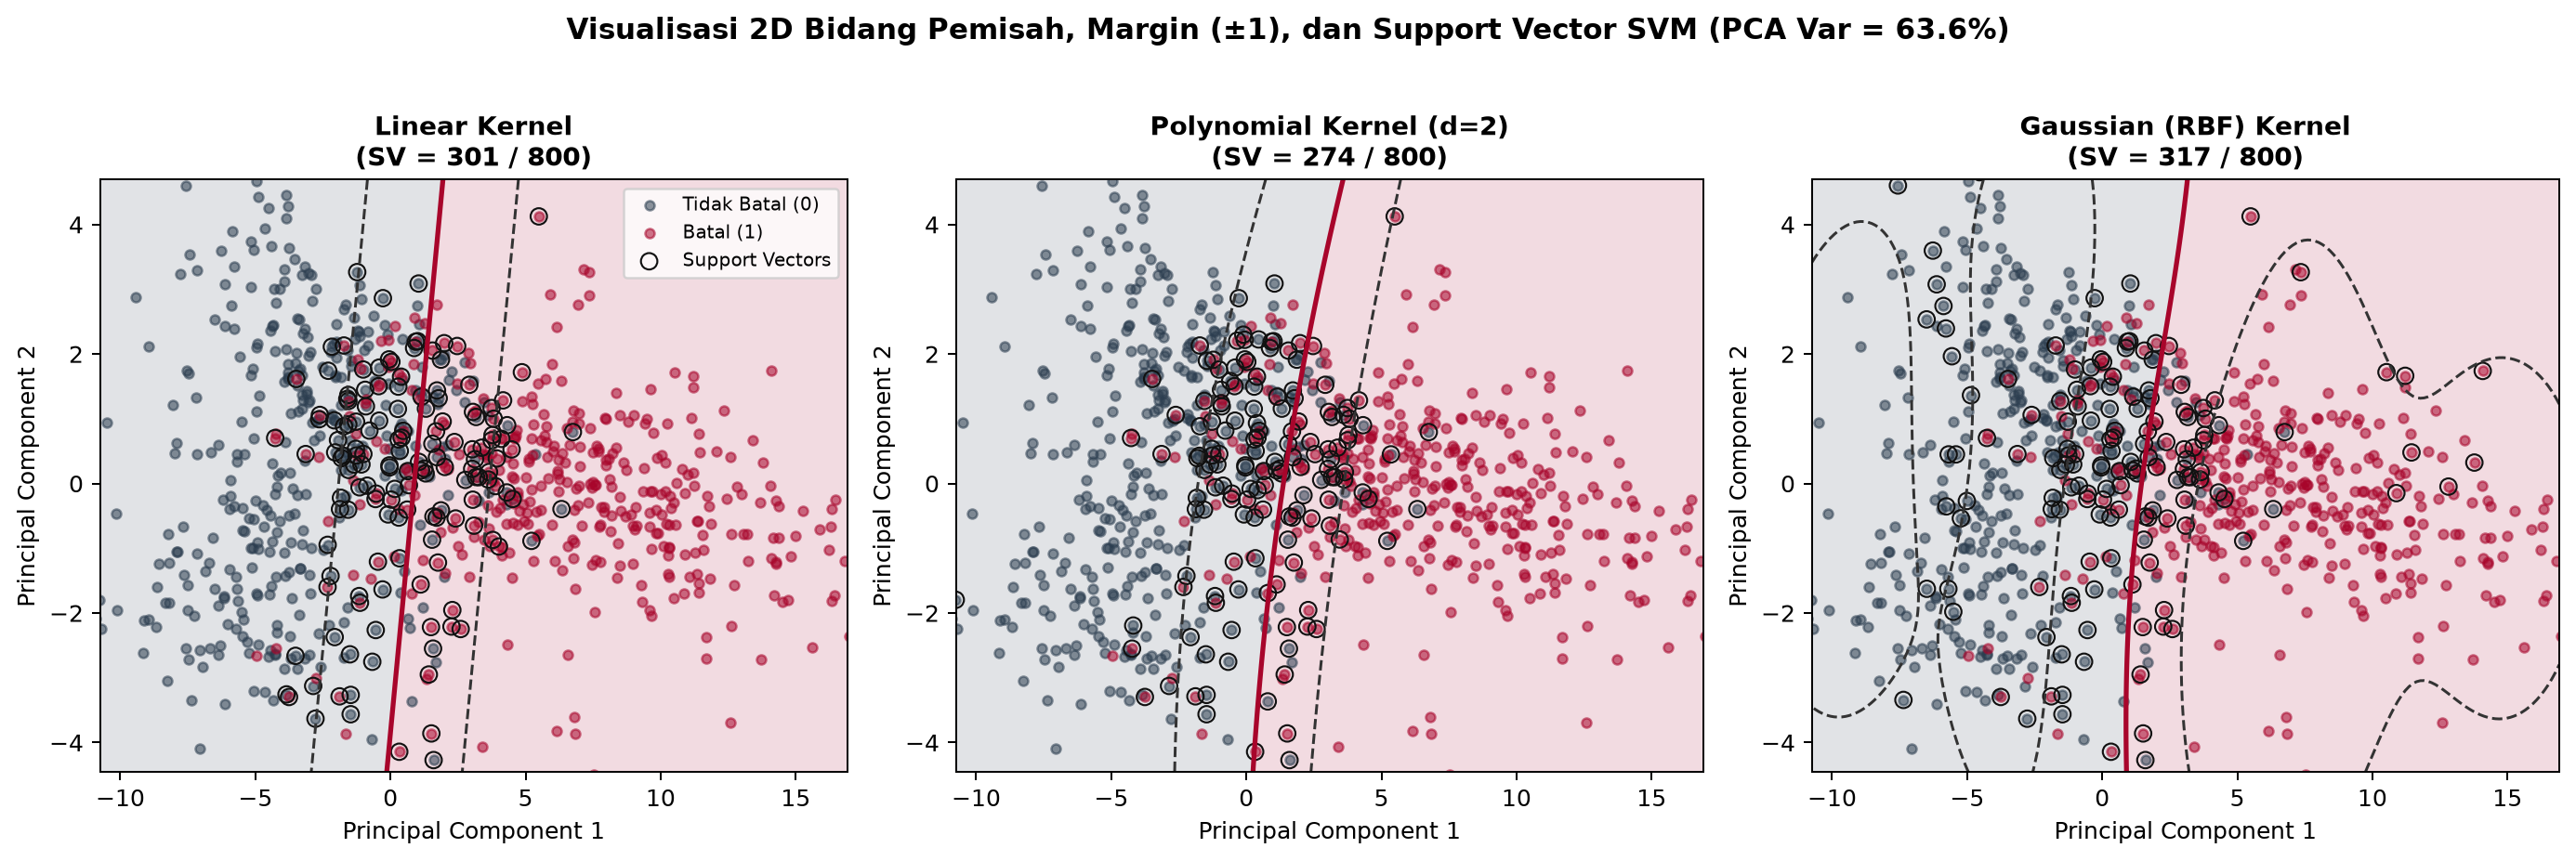

In [20]:
pca = PCA(n_components=2, random_state=CFG.SEED)
X_2d = pca.fit_transform(X_train_model)
exp_var = pca.explained_variance_ratio_.sum() * 100.0

rng_vis = np.random.default_rng(CFG.SEED)
idx0 = rng_vis.choice(np.flatnonzero(y_train == 0), size=400, replace=False)
idx1 = rng_vis.choice(np.flatnonzero(y_train == 1), size=400, replace=False)
sub_idx = np.sort(np.concatenate([idx0, idx1]))
Xs = X_2d[sub_idx]
ys = y_train[sub_idx]

x_min, x_max = np.percentile(Xs[:, 0], 1) - 0.6, np.percentile(Xs[:, 0], 99) + 0.6
y_min, y_max = np.percentile(Xs[:, 1], 1) - 0.6, np.percentile(Xs[:, 1], 99) + 0.6
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
grid = np.column_stack([xx.ravel(), yy.ravel()])

fig, axes = plt.subplots(1, 3, figsize=(15.5, 5.0), dpi=180)
vis_configs = [
    ('Linear Kernel', dict(C=0.5, kernel='linear', class_weight='balanced', solver='smo', max_iter=60)),
    ('Polynomial Kernel (d=2)', dict(C=1.0, kernel='poly', degree=2, gamma='scale', coef0=1.0, class_weight='balanced', solver='smo', max_iter=60)),
    ('Gaussian (RBF) Kernel', dict(C=1.0, kernel='rbf', gamma='scale', class_weight='balanced', solver='smo', max_iter=60)),
]

primary_color = '#a8052b'
for ax, (title, kw) in zip(axes, vis_configs):
    m_vis = SVMFromScratch(random_state=CFG.SEED, **kw)
    m_vis.fit(Xs, ys)
    zz = m_vis.decision_function(grid).reshape(xx.shape)

    ax.contourf(xx, yy, zz, levels=[-1e3, 0.0, 1e3], colors=['#2c3e50', primary_color], alpha=0.14)
    ax.contour(
        xx, yy, zz,
        levels=[-1.0, 0.0, 1.0],
        colors=['#333333', primary_color, '#333333'],
        linestyles=['--', '-', '--'],
        linewidths=[1.2, 2.1, 1.2],
    )
    ax.scatter(Xs[ys == 0, 0], Xs[ys == 0, 1], c='#2c3e50', s=16, alpha=0.55, label='Tidak Batal (0)')
    ax.scatter(Xs[ys == 1, 0], Xs[ys == 1, 1], c=primary_color, s=16, alpha=0.55, label='Batal (1)')
    if m_vis.support_vectors_ is not None:
        sv = m_vis.support_vectors_[:150]
        ax.scatter(sv[:, 0], sv[:, 1], s=50, facecolors='none', edgecolors='#111111', linewidths=0.85, label='Support Vectors')

    ax.set_title(f'{title}\n(SV = {m_vis.n_support_} / {len(Xs)})', fontsize=11, fontweight='bold')
    ax.set_xlabel('Principal Component 1')
    ax.set_ylabel('Principal Component 2')
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)

axes[0].legend(loc='upper right', fontsize=8, frameon=True)
fig.suptitle(f'Visualisasi 2D Bidang Pemisah, Margin (±1), dan Support Vector SVM (PCA Var = {exp_var:.1f}%)', fontsize=12.5, fontweight='bold', y=1.02)
plt.tight_layout()

img_out = CFG.ROOT_DIR / 'docs' / 'laporan-akhir' / 'public' / '04-hasil-eksperimen-dan-analisis' / 'svm_2d_boundary.png'
img_out.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(img_out, bbox_inches='tight')
print(f'Saved 2D boundary plot to {img_out} (PCA explained variance: {exp_var:.2f}%)')
plt.show()